In [2]:
# Check that GPU is used
import tensorflow as tf
tf.config.list_physical_devices('GPU')

[]

In [3]:
from PIL import Image
import os
import numpy as np

# Define the folders where your data is stored
train_folder = 'chest_xray/train'
test_folder = 'chest_xray/test'
val_folder = 'chest_xray/val'

# Define the subfolders within each folder where the images are stored
subfolders = ['NORMAL', 'VIRUS', 'BACTERIA']

# Define the size of the images you want to resize your images to
img_width, img_height = 128, 128

In [4]:
def split_virus_bacteria_pneumonia(folder):
    temp_subfolders = ['NORMAL', 'VIRUS', 'BACTERIA']

    # Create the subfolders if they don't exist
    for subfolder in subfolders:
        if not os.path.exists(os.path.join(folder, subfolder)):
            os.makedirs(os.path.join(folder, subfolder))

    # Move the images to the corresponding subfolder
    for subfolder in temp_subfolders:
        subfolder_path = os.path.join(folder, subfolder)
        if subfolder == 'PNEUMONIA':
            for filename in os.listdir(subfolder_path):
                if 'virus' in filename:
                    os.rename(os.path.join(subfolder_path, filename), os.path.join(folder, 'VIRUS', filename))
                elif 'bacteria' in filename:
                    os.rename(os.path.join(subfolder_path, filename), os.path.join(folder, 'BACTERIA', filename))
        else:
            for filename in os.listdir(subfolder_path):
                os.rename(os.path.join(subfolder_path, filename), os.path.join(folder, subfolder, filename))

In [5]:
# Split the pneumonia folder into virus and bacteria subfolders
split_virus_bacteria_pneumonia(train_folder)

# Split the pneumonia folder into virus and bacteria subfolders
split_virus_bacteria_pneumonia(test_folder)

# Split the pneumonia folder into virus and bacteria subfolders
split_virus_bacteria_pneumonia(val_folder)

In [7]:
# Function to load and resize images from a folder
def load_images_from_folder(folder, limit_per_subfolder=None):
    X = []
    y = []
    for subfolder in subfolders:
        folder_path = os.path.join(folder, subfolder)
        if limit_per_subfolder:
            # Get amount of random filenames from the folder
            filenames = np.random.choice(os.listdir(folder_path), limit_per_subfolder, replace=False)
        else:
            filenames = os.listdir(folder_path)
        for filename in filenames:
            img_path = os.path.join(folder_path, filename)
            img = Image.open(img_path)

            # Resize the image to the desired size
            img = img.resize((img_width, img_height))

            img = img.convert('RGB')

            # Convert the image to a NumPy array and append it to X
            img = np.array(img)
            X.append(img)

            # Append the corresponding label to y
            y.append(subfolders.index(subfolder))

    X = np.array(X)
    y = np.array(y)
    return X, y

In [8]:
# Generate augmented for the training set
from data_augmentation import generate_augmented_images
generate_augmented_images(train_folder, 'NORMAL', image_size=(img_width, img_height))
generate_augmented_images(train_folder, 'BACTERIA', image_size=(img_width, img_height))
generate_augmented_images(train_folder, 'VIRUS', image_size=(img_width, img_height))

Found 1341 images belonging to 1 classes.
Additional count of images to generate: 0
Given NORMAL count: 1341
Augmented NORMAL count: 5000
Found 2530 images belonging to 1 classes.
Additional count of images to generate: 0
Given BACTERIA count: 2530
Augmented BACTERIA count: 5000
Found 1345 images belonging to 1 classes.
Additional count of images to generate: 0
Given VIRUS count: 1345
Augmented VIRUS count: 5000


In [9]:
# Load the training data
# Get min value between the number of normal images and the number of pneumonia images
train_folder = train_folder if train_folder.endswith('_augmented') else f"{train_folder}_augmented"
min_images = min(len(os.listdir(os.path.join(train_folder, subfolders[0]))), len(os.listdir(os.path.join(train_folder, subfolders[1]))), len(os.listdir(os.path.join(train_folder, subfolders[2]))))
X_train, y_train = load_images_from_folder(train_folder, min_images)

# Load the test data
X_test, y_test = load_images_from_folder(test_folder)

# Load the validation data
X_val, y_val = load_images_from_folder(val_folder)

In [10]:
# One-hot encode the labels
from tensorflow.keras.utils import to_categorical
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)
y_val = to_categorical(y_val)

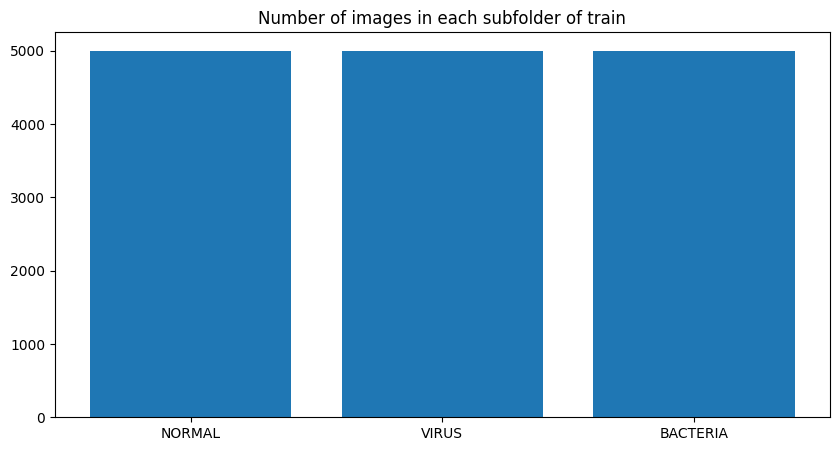

In [11]:
# Make a matplot figure to show how many images are in each subfolder of train
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.bar(subfolders, [len(os.listdir(os.path.join(train_folder, subfolder))) for subfolder in subfolders])
plt.title('Number of images in each subfolder of train')
plt.show()

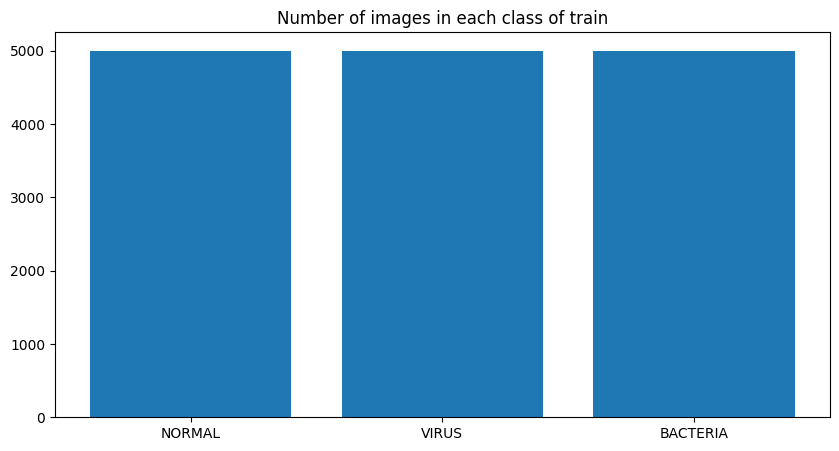

In [12]:
# Make a matplot figure to show how many images if each class in the training set considering it is hot-encoded
plt.figure(figsize=(10, 5))
plt.bar(subfolders, [sum(y_train[:, i]) for i in range(len(subfolders))])
plt.title('Number of images in each class of train')
plt.show()

In [13]:
# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255
X_test = X_test.astype('float32') / 255
X_val = X_val.astype('float32') / 255

X_train = X_train.reshape(len(X_train), img_width, img_height, 3)
X_test = X_test.reshape(len(X_test), img_width, img_height, 3)
X_val = X_val.reshape(len(X_val), img_width, img_height, 3)

(128, 128, 3)


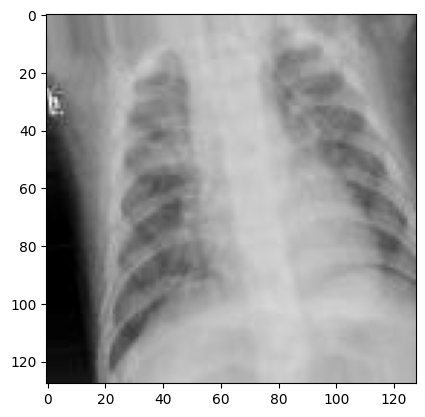

In [14]:
single_image = X_train[np.random.randint(len(X_train))]
print(single_image.shape)
plt.imshow(single_image, cmap='Greys')

In [15]:
# Define model metrics
from keras.metrics import AUC

metrics = [
    "accuracy",
    AUC(name='auc')
]

In [16]:
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

def create_model():
    # Charge DenseNet sans la couche finale (include_top=False)
    base_model = DenseNet121(
        include_top=False,
        weights='imagenet',
        input_shape=(img_width, img_height, 3)  
    )

    # On gèle les premières couches (optionnel au départ)
    base_model.trainable = False

    model = Sequential()
    model.add(base_model)
    model.add(GlobalAveragePooling2D())
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(128, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(3, activation='softmax'))

    # compile le modèle
    model.compile(loss="categorical_crossentropy", optimizer=Adam(), metrics=metrics)

    return model


In [21]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='loss', patience=3, restore_best_weights=True)

In [17]:
from sklearn.model_selection import KFold
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# Cross-validation parameters
n_splits = 5
epochs = 14
fine_tune_epochs = 6  # nombre d’epochs pour le fine-tuning
batch_size = 32

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)

accuracy_scores = []
histories = []
models = []

datagen = ImageDataGenerator()
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train, y_train)):
    print(f"\nFold {fold+1}/{n_splits}")

    X_train_fold, y_train_fold = X_train[train_idx], y_train[train_idx]
    X_val_fold, y_val_fold = X_train[val_idx], y_train[val_idx]

    train_generator = datagen.flow(X_train_fold, y_train_fold, batch_size=batch_size)
    val_generator = datagen.flow(X_val_fold, y_val_fold, batch_size=batch_size)

    model = create_model()  # base_model gelé

    # 🧪 Phase 1 : pré-entraînement
    print("Entraînement de la tête (base_model gelé)")
    model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=epochs,
        callbacks=[early_stop],
        verbose=1
    )

    # 🧠 Phase 2 : Fine-tuning
    print("Fine-tuning des dernières couches de DenseNet")
    base_model = model.layers[0]
    base_model.trainable = True

    # Dégèle les dernières N couches
    fine_tune_at = 400
    for i, layer in enumerate(base_model.layers):
        layer.trainable = i >= fine_tune_at

    # Recompile avec petit learning rate
    model.compile(
        optimizer=Adam(learning_rate=1e-5),
        loss='categorical_crossentropy',
        metrics=['accuracy', 'AUC']
    )

    # Réentraînement (fine-tuning)
    history_ft = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=fine_tune_epochs,
        callbacks=[early_stop, reduce_lr],
        verbose=1
    )

    # Fusionner les historiques (optionnel)
    history_combined = {
        key: history_ft.history.get(key, []) + model.history.history.get(key, [])
        for key in set(history_ft.history.keys()).union(model.history.history.keys())
    }
    histories.append(history_combined)
    models.append(model)

    acc = model.evaluate(val_generator, verbose=0)[1]
    accuracy_scores.append(acc)
    print(f"Accuracy du fold {fold+1} : {acc:.4f}")



Fold 1/5
Entraînement de la tête (base_model gelé)
Epoch 1/14


c:\Users\paul4\Documents\T-DEV-810\T-DEV-810-NAN_1\.venv\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


375/375 ━━━━━━━━━━━━━━━━━━━━ 224s 572ms/step - accuracy: 0.5435 - auc: 0.7357 - loss: 1.0410 - val_accuracy: 0.7300 - val_auc: 0.8946 - val_loss: 0.6184
Epoch 2/14
375/375 ━━━━━━━━━━━━━━━━━━━━ 246s 657ms/step - accuracy: 0.6973 - auc: 0.8745 - loss: 0.6665 - val_accuracy: 0.7507 - val_auc: 0.9094 - val_loss: 0.5696
Epoch 3/14
375/375 ━━━━━━━━━━━━━━━━━━━━ 242s 646ms/step - accuracy: 0.7113 - auc: 0.8864 - loss: 0.6342 - val_accuracy: 0.7537 - val_auc: 0.9095 - val_loss: 0.5741
Epoch 4/14
375/375 ━━━━━━━━━━━━━━━━━━━━ 244s 647ms/step - accuracy: 0.7299 - auc: 0.8982 - loss: 0.5993 - val_accuracy: 0.7513 - val_auc: 0.9075 - val_loss: 0.5797
Epoch 5/14
375/375 ━━━━━━━━━━━━━━━━━━━━ 248s 662ms/step - accuracy: 0.7305 - auc: 0.8974 - loss: 0.5992 - val_accuracy: 0.7567 - val_auc: 0.9143 - val_loss: 0.5567
Epoch 6/14
375/375 ━━━━━━━━━━━━━━━━━━━━ 247s 658ms/step - accuracy: 0.7421 - auc: 0.9070 - loss: 0.5701 - val_accuracy: 0.7597 - val_auc: 0.9150 - val_loss: 0.5532
Epoch 7/14
375/375 ━━━━━━━━

In [18]:
# Get accuracy scores for each fold (train and validation)
loss = []
acc = []
val_loss = []
val_acc = []

for history in histories:
    loss.append(np.mean(history["loss"]))
    acc.append(np.mean(history["accuracy"]))
    val_loss.append(np.mean(history["val_loss"]))
    val_acc.append(np.mean(history["val_accuracy"]))

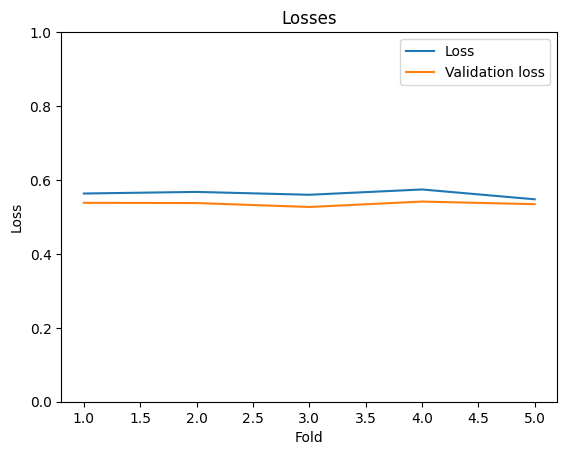

In [19]:
# Plot loss and validation loss per fold
import matplotlib.pyplot as plt
plt.title('Losses')
plt.plot(range(1, len(loss)+1), loss, label='Loss')
plt.plot(range(1, len(val_loss)+1), val_loss, label='Validation loss')
plt.ylim(0.0, 1.0)
plt.xlabel('Fold')
plt.ylabel('Loss')
plt.legend()
plt.show()

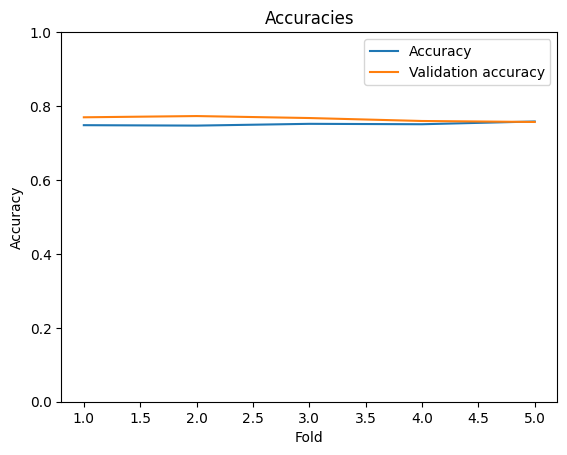

In [20]:
# Plot accuracies and validation accuracies per fold
import matplotlib.pyplot as plt
plt.title('Accuracies')
plt.plot(range(1, len(acc)+1), acc, label='Accuracy')
plt.plot(range(1, len(val_acc)+1), val_acc, label='Validation accuracy')
plt.ylim(0.0, 1.0)
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# Train a final model with same parameters and save it
train_generator = datagen.flow(x=X_train, y=y_train, batch_size=batch_size)
valid_generator = datagen.flow(x=X_val, y=y_val, batch_size=batch_size)
model = create_model()
history = model.fit(train_generator, validation_data=valid_generator, epochs=7, verbose=1, callbacks=[early_stop])
model.save('densenet.h5')

Epoch 1/7


c:\Users\paul4\Documents\T-DEV-810\T-DEV-810-NAN_1\.venv\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


469/469 ━━━━━━━━━━━━━━━━━━━━ 235s 475ms/step - accuracy: 0.5736 - auc: 0.8211 - loss: 0.9901 - val_accuracy: 0.3611 - val_auc: 0.6844 - val_loss: 0.9012
Epoch 2/7
469/469 ━━━━━━━━━━━━━━━━━━━━ 218s 465ms/step - accuracy: 0.7059 - auc: 0.8780 - loss: 0.6615 - val_accuracy: 0.3333 - val_auc: 0.6777 - val_loss: 1.0472
Epoch 3/7
469/469 ━━━━━━━━━━━━━━━━━━━━ 216s 460ms/step - accuracy: 0.7270 - auc: 0.8943 - loss: 0.6104 - val_accuracy: 0.3611 - val_auc: 0.6779 - val_loss: 1.0764
Epoch 4/7
162/469 ━━━━━━━━━━━━━━━━━━━━ 2:25 475ms/step - accuracy: 0.7246 - auc: 0.8918 - loss: 0.6263

AttributeError: 'dict' object has no attribute 'history'

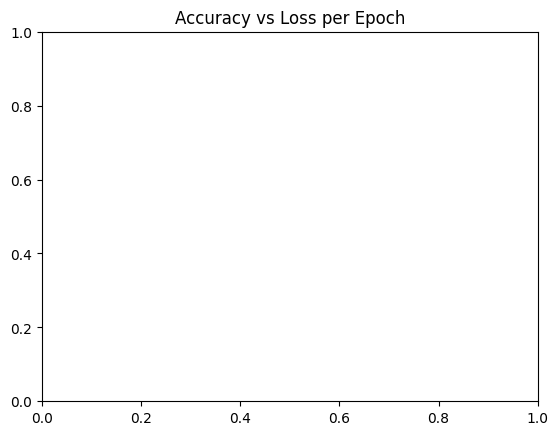

In [22]:
# Plot val accuracy and val loss of the trained model
import matplotlib.pyplot as plt
plt.title('Accuracy vs Loss per Epoch')
plt.plot(range(1, len(history.history["val_accuracy"])+1), history.history["val_accuracy"], label='Accuracy')
plt.plot(range(1, len(history.history["val_loss"])+1), history.history["val_loss"], label='Loss')
plt.ylim(0.0, 1.0)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [30]:
# Make predictions on the test set
y_pred_test = model.predict(X_test)
y_pred_test = np.where(y_pred_test >= 0.5, 1, 0)

20/20 ━━━━━━━━━━━━━━━━━━━━ 17s 698ms/step


In [31]:
# convert one-hot encoded y_test to class labels
y_test_labels = np.argmax(y_test, axis=1)

# convert y_pred_test to class labels
y_pred_labels = np.argmax(y_pred_test, axis=1)

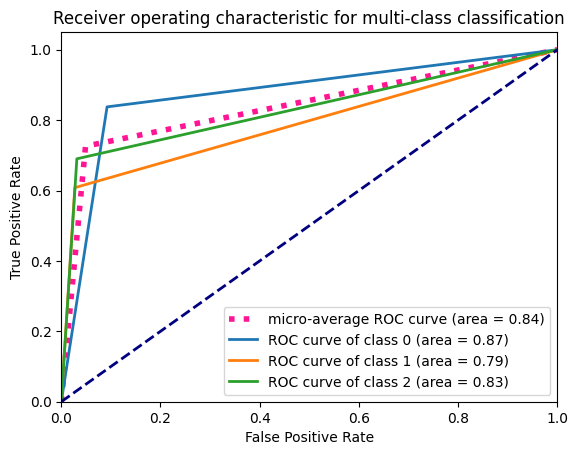

In [32]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Compute ROC curve and AUC score for each class
fpr = {}
tpr = {}
roc_auc = {}
for i in range(len(subfolders)):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_pred_test[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and AUC score
fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_pred_test.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Plot ROC curve for each class and show AUC score on the plot
plt.figure()
lw = 2
plt.plot(fpr["micro"], tpr["micro"], color='deeppink', linestyle=':', linewidth=4, label='micro-average ROC curve (area = {0:0.2f})'.format(roc_auc["micro"]))
for i in range(len(subfolders)):
    plt.plot(fpr[i], tpr[i], lw=lw, label='ROC curve of class {0} (area = {1:0.2f})'.format(i, roc_auc[i]))

# Plot random guess line
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

# Set plot title and labels
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic for multi-class classification')
plt.legend(loc="lower right")
plt.show()

In [34]:
from sklearn.metrics import confusion_matrix
# compute confusion matrix
cm = confusion_matrix(y_test_labels, y_pred_labels)
print(cm)

[[223  11   0]
 [ 46  90  12]
 [ 73   2 167]]


In [23]:
# Plot the confusion matrix
class_names = subfolders
import seaborn as sns
sns.heatmap(cm, annot=True, fmt='g', cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

NameError: name 'cm' is not defined

In [37]:
# Compute the classification report for test set
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_test, target_names=class_names))

              precision    recall  f1-score   support

      NORMAL       0.84      0.84      0.84       234
       VIRUS       0.87      0.61      0.72       148
    BACTERIA       0.93      0.69      0.79       242

   micro avg       0.88      0.73      0.80       624
   macro avg       0.88      0.71      0.78       624
weighted avg       0.89      0.73      0.79       624
 samples avg       0.73      0.73      0.73       624



c:\Users\paul4\Documents\T-DEV-810\T-DEV-810-NAN_1\.venv\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


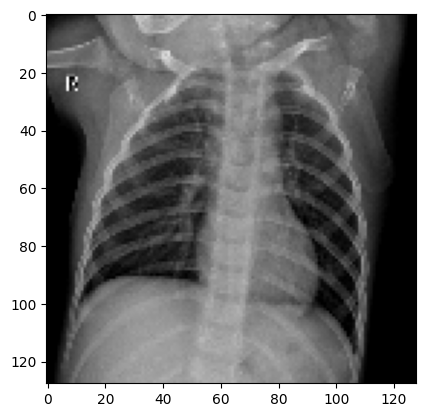

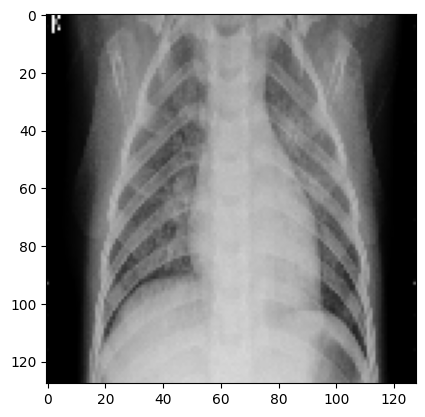

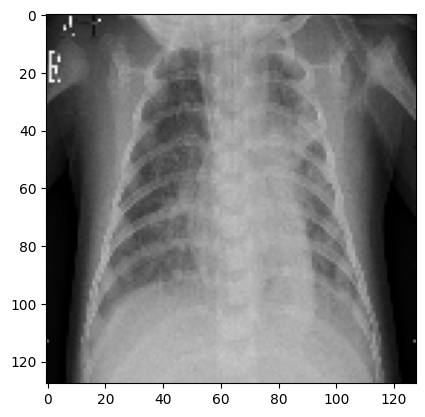

In [38]:
# Heatmaps and Grad-CAM
from common import get_img_array
import cv2
import matplotlib.pyplot as plt 

images = [
    {
            "path": "./chest_xray/val/NORMAL/NORMAL2-IM-1442-0001.jpeg",
            "array": get_img_array("./chest_xray/val/NORMAL/NORMAL2-IM-1442-0001.jpeg", size=(256, 256))  # par exemple

    },
    {
        "path": "./chest_xray/val/VIRUS/person83_virus_156.jpeg",
        "array": get_img_array("./chest_xray/val/VIRUS/person83_virus_156.jpeg", size=(256, 256))  # par exemple

    },
    {
        "path": "./chest_xray/val/BACTERIA/person1946_bacteria_4874.jpeg",
        "array": get_img_array("./chest_xray/val/BACTERIA/person1946_bacteria_4874.jpeg", size=(256, 256))  # par exemple
    },
]

for image in images:
    image_temp = cv2.imread(image["path"])
    image_temp = cv2.cvtColor(image_temp, cv2.COLOR_RGB2GRAY)
    image_temp = cv2.resize(image_temp, (img_width, img_height))

    plt.imshow(image_temp, cmap=plt.cm.gray)
    plt.show()
    
    image["array"] = get_img_array(image["path"], size=(img_width, img_height))

In [39]:
# Remove last layer's softmax
model.layers[-1].activation = None

# import os
# os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

In [40]:
# Print model summary to get last max pooling layer name
print(model.summary())

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 4, 4, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,924,555 (30.23 MB)

 Trainable params: 295,683 (1.13 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

 Optimizer params: 591,368 (2.26 MB)

None
